<h1>2D Fiber Scattering Example</h1>

Load a saved matter-interface geometry, then run a one-photon scattering experiment.

In [28]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

import numpy as np

resol = 200
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
    "mathtext.fontset": "cm",
    "axes.linewidth": 0.7,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
})

cwd = Path().resolve()
setup_root = next(
    (
        path
        for path in (cwd, *cwd.parents)
        if (path / "database_fiber").exists() and (path / "src").exists()
    ),
    Path("2d_setup").resolve(),
)
sys.path.insert(0, str(setup_root))

from src.experiment import Experiment
from src.generate_fiber_geom import load_geometry_by_id
from src.bare_param import make_fiber_config

pi = np.pi


<h2>Load matter geometry</h2>

In [11]:
geometry_id = 5
geometry = load_geometry_by_id(geometry_id)

L1, L2 = geometry["lengths"]
N_A = geometry["N_A"]
atom_positions = geometry["atom_positions"]

print(f"Loaded geometry: {geometry['path'].name}")
print(f"lengths={geometry['lengths']}, N_A={N_A}, N_layer={geometry['N_layer']}, kind={geometry['kind']}")


Loaded geometry: geometry_id5.csv
lengths=[5. 5.], N_A=10, N_layer=1, kind=slab


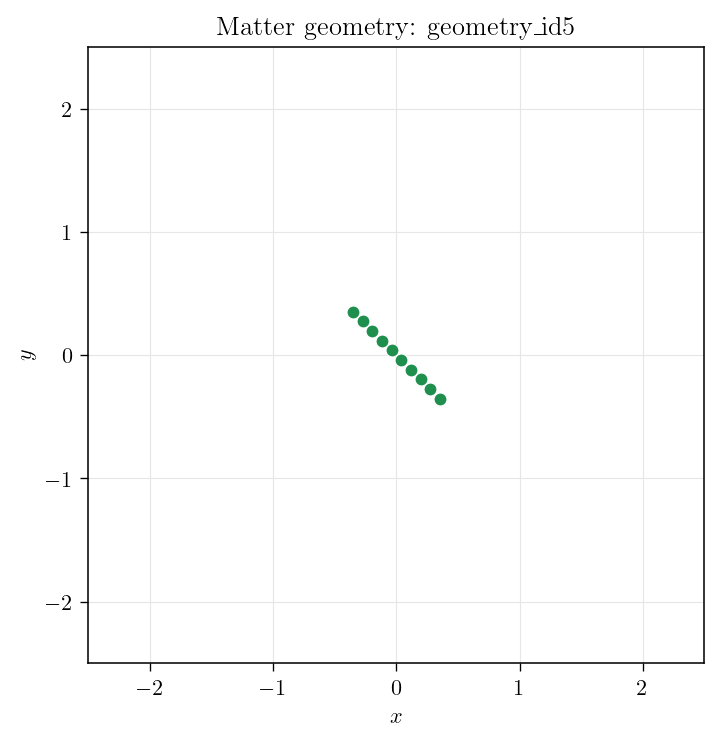

In [12]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=resol)
ax.scatter(
    atom_positions[:, 0],
    atom_positions[:, 1],
    s=34,
    color="#1f8f4d",
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)
ax.set_xlim(-L1 / 2, L1 / 2)
ax.set_ylim(-L2 / 2, L2 / 2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.grid(color="0.9", linewidth=0.5)
latex_label = geometry["label"].replace("_", r"\_")
ax.set_title(f"Matter geometry: {latex_label}")
plt.show()


<h2>Experiment parameters</h2>

In [13]:
Omega_A_tab = 10 * np.pi * np.ones(N_A)
d_A_tab = np.ones(N_A, dtype=float)

omega_init = 10 * np.pi
param_photon = {
    "p_0": [omega_init, 0.0],
    "sigma_p": [np.pi, np.pi],
    "x_0": [-L1 / 4, 0.0],
}

param_time_evol = {"T": L1 / 2, "dt": 0.01}
cutoffs = {"ir_cutoff": 0 * np.pi, "uv_cutoff": 20 * np.pi}
use_correction = False

param_atom = {
    "Omega_A": Omega_A_tab,
    "d_A": d_A_tab,
    "geometry": geometry,
}

config = make_fiber_config(
    param_photon=param_photon,
    param_atom=param_atom,
    param_time_evol=param_time_evol,
    cutoffs=cutoffs,
    correction=use_correction,
)

scattering_experiment = Experiment(config)

print(f"Config dimension: {config.dimension}")
print(f"Config atom count: {scattering_experiment.n_atoms}")
print(f"Target Omega_A/pi: {Omega_A_tab[0] / np.pi:.6f}")
print(f"Target d_A: {d_A_tab[0]:.6f}")
print(f"Correction enabled: {use_correction}")


Config dimension: 2
Config atom count: 10
Target Omega_A/pi: 10.000000
Target d_A: 1.000000
Correction enabled: False


<h2>Run the propagation</h2>

In [14]:
c_array, b_array = scattering_experiment.propagate_state(progress=True)
messages = scattering_experiment.get_messages()

time_array = scattering_experiment.times
An_array, Tn_array, Rn_array = scattering_experiment.compute_observables()
forward_array = scattering_experiment.forward_array
backward_array = scattering_experiment.backward_array
side_array = scattering_experiment.side_array
total_array = Tn_array + Rn_array + An_array

print(f"Final reflection/scattering: {Rn_array[-1]:.6f}")
print(f"Final packet transmission: {Tn_array[-1]:.6f}")
print(f"Final atomic excitation: {An_array[-1]:.6f}")
print(f"Final total probability: {total_array[-1]:.12f}")


100%|██████████| 250/250 [00:03<00:00, 65.24it/s]

Final reflection/scattering: 0.624047
Final packet transmission: 0.375886
Final atomic excitation: 0.000066
Final total probability: 1.000000037923


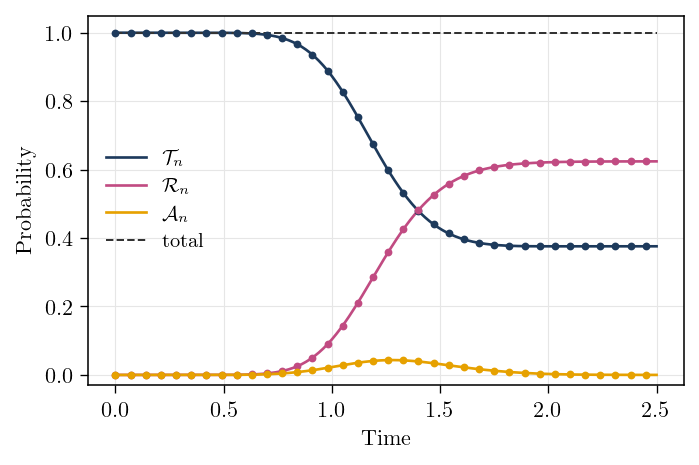

In [15]:
fig, ax = plt.subplots(figsize=(4.8, 3.0), dpi=resol)

step_marker = max(1, len(time_array) // 35)
color_Tn = "#1d3a5c"
color_Rn = "#c14b82"
color_atom = "#e6a100"

ax.plot(time_array, Tn_array, color=color_Tn, lw=1.2, label=r"$\mathcal{T}_n$")
ax.plot(time_array, Rn_array, color=color_Rn, lw=1.2, label=r"$\mathcal{R}_n$")
ax.plot(time_array, An_array, color=color_atom, lw=1.2, label=r"$\mathcal{A}_n$")
ax.plot(time_array, total_array, color="0.2", lw=0.9, ls="--", label=r"$\mathrm{total}$")

ax.plot(time_array[::step_marker], Tn_array[::step_marker], "o", ms=2.5, color=color_Tn)
ax.plot(time_array[::step_marker], Rn_array[::step_marker], "o", ms=2.5, color=color_Rn)
ax.plot(time_array[::step_marker], An_array[::step_marker], "o", ms=2.5, color=color_atom)

ax.set_xlabel(r"$\mathrm{Time}$")
ax.set_ylabel(r"$\mathrm{Probability}$")
ax.set_ylim(-0.03, 1.05)
ax.grid(color="0.9", linewidth=0.5)
ax.legend(frameon=False, fontsize=9)
plt.show()


<h2>Photon distribution</h2>

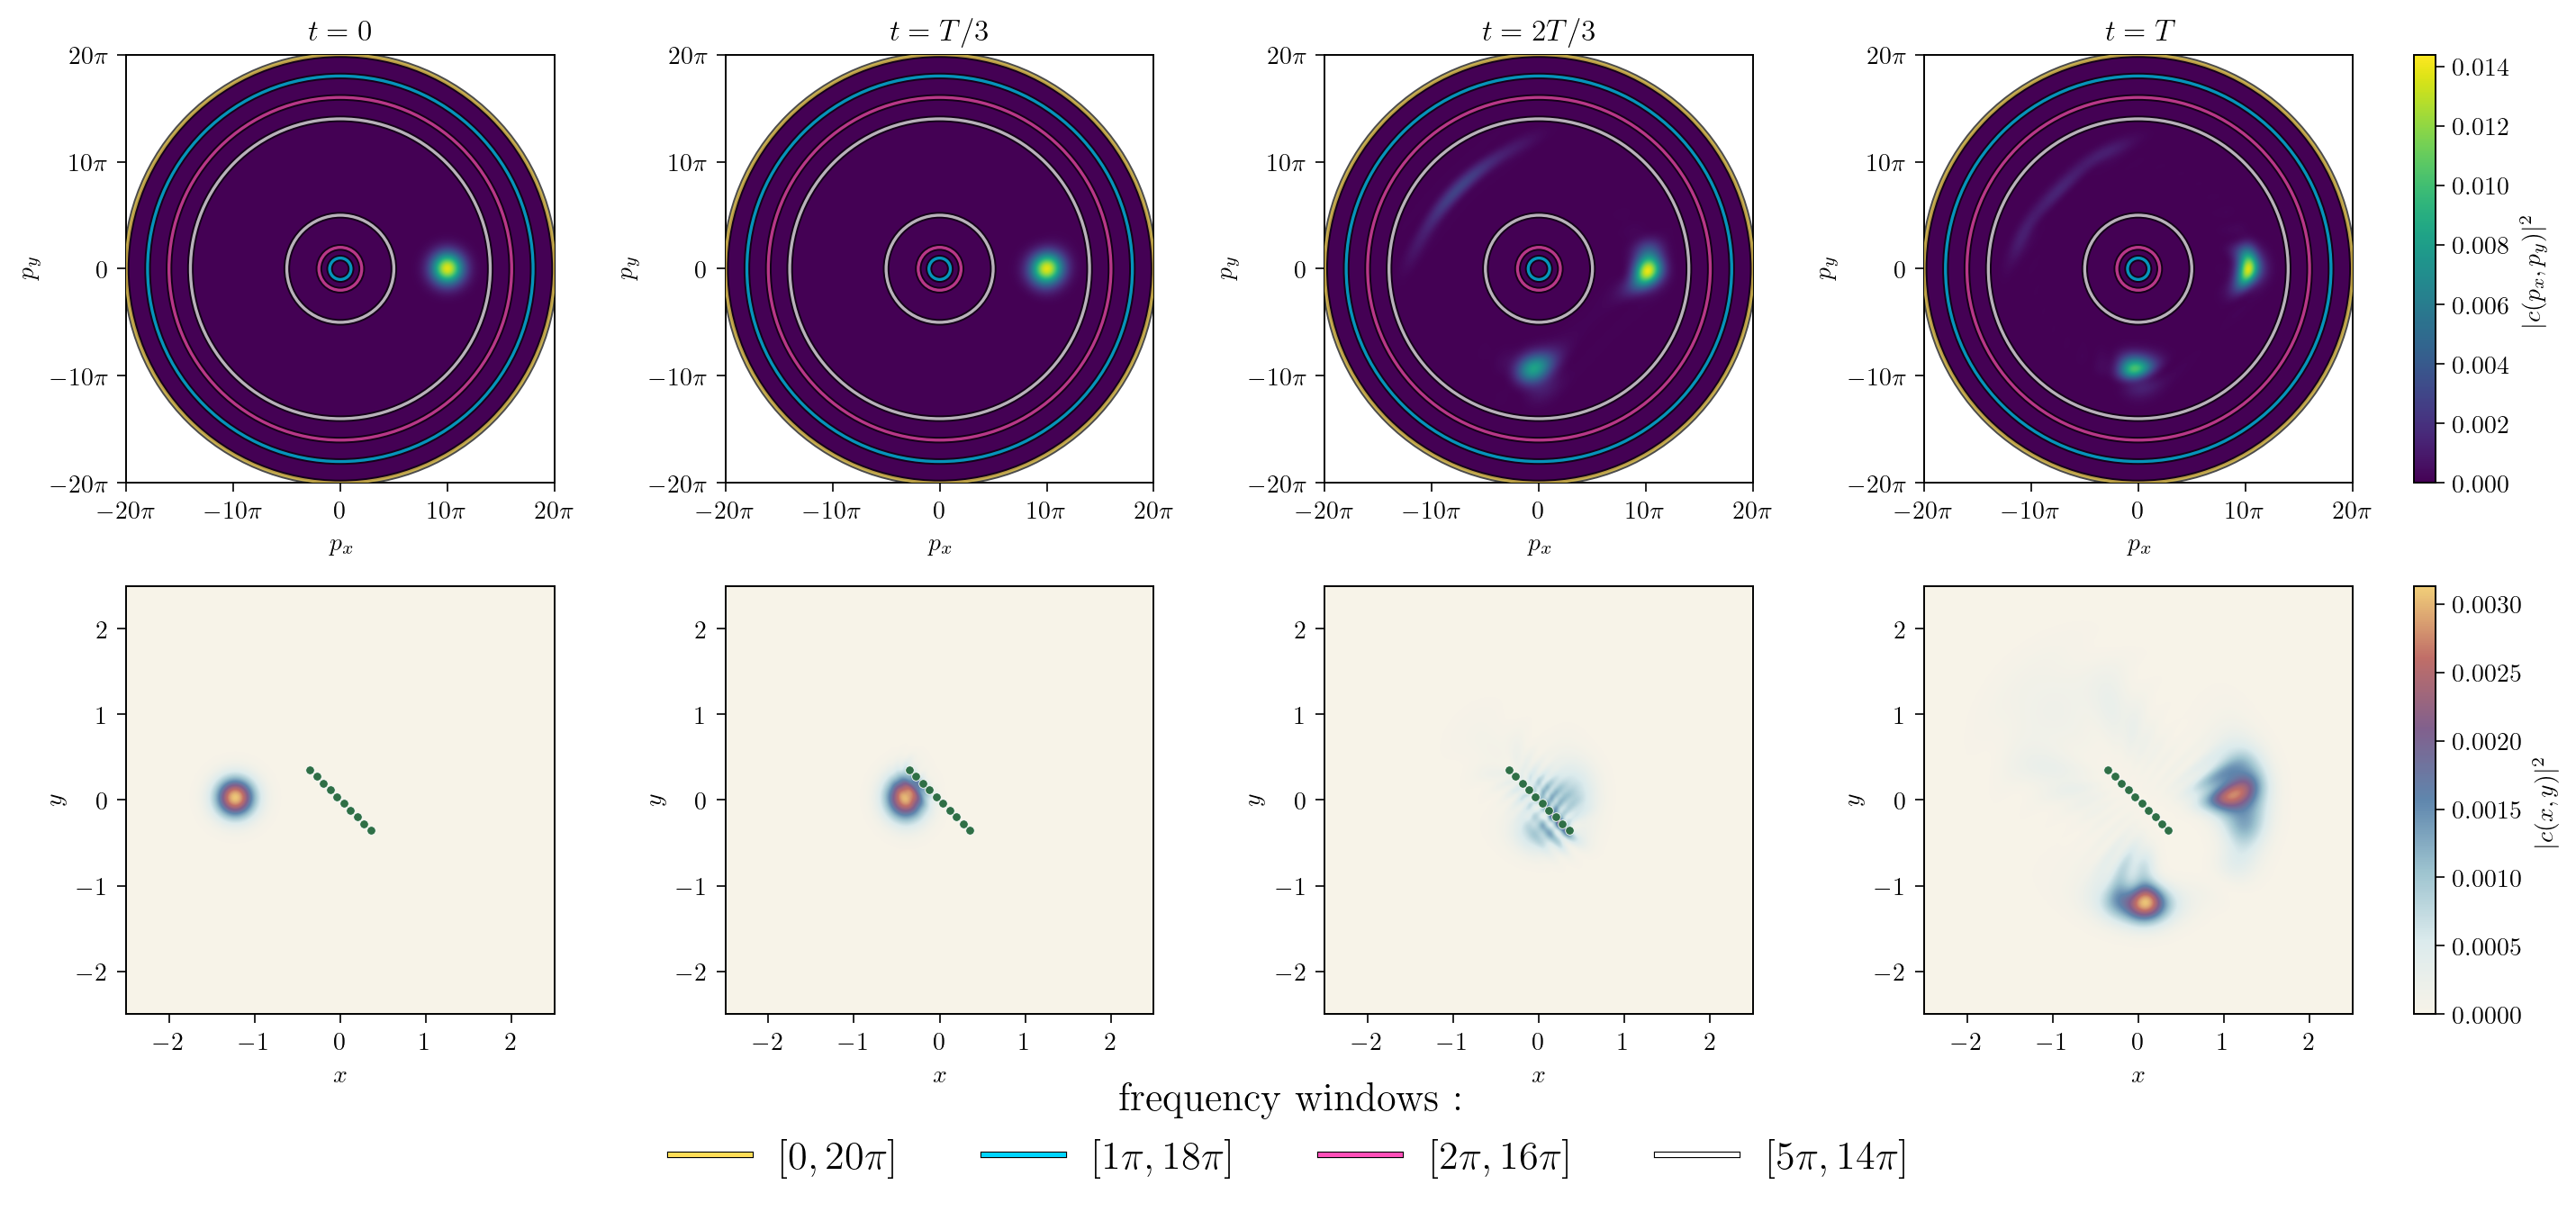

In [33]:
# Direct discrete probability transform: readable version.
snapshot_fractions = [0, 1 / 3, 2 / 3, 1]
snapshot_labels = [r"$t=0$", r"$t=T/3$", r"$t=2T/3$", r"$t=T$"]
snapshot_indices = [
    int(np.argmin(np.abs(scattering_experiment.times - fraction * scattering_experiment.times[-1])))
    for fraction in snapshot_fractions
]
frequency_windows = [
    (0 * np.pi, 20 * np.pi, "#ffdd57", "-"),
    (1 * np.pi, 18 * np.pi, "#00d4ff", "-"),
    (2 * np.pi, 16 * np.pi, "#ff4fb8", "-"),
    (5 * np.pi, 14 * np.pi, "#ffffff", "-"),
]
plot_interpolation = "bicubic"
outer_frequency_limit = max(outer for _, outer, _, _ in frequency_windows)
momentum_ticks = np.array([-20, -10, 0, 10, 20]) * np.pi
momentum_tick_labels = [r"$-20\pi$", r"$-10\pi$", r"$0$", r"$10\pi$", r"$20\pi$"]

n_abs_max = np.max(np.abs(scattering_experiment.mode_indices), axis=0)
position_shape = tuple((2 * n_abs_max + 1).astype(int))
n_position_points = np.prod(position_shape)
x = np.linspace(-L1 / 2, L1 / 2, position_shape[0], endpoint=False)
y = np.linspace(-L2 / 2, L2 / 2, position_shape[1], endpoint=False)
x_grid, y_grid = np.meshgrid(x, y, indexing="xy")
position_points = np.column_stack((x_grid.ravel(), y_grid.ravel()))


def compute_position_probability(c_p, t, chunk_size=512):
    c_t = c_p * np.exp(-1j * scattering_experiment.omega_tab * t)
    c_pos = np.empty(len(position_points), dtype=complex)
    for start in range(0, len(position_points), chunk_size):
        stop = min(start + chunk_size, len(position_points))
        phase = np.exp(1j * position_points[start:stop] @ scattering_experiment.momenta.T)
        c_pos[start:stop] = phase @ c_t / np.sqrt(n_position_points)
    return np.abs(c_pos.reshape(position_shape[1], position_shape[0])) ** 2

mode_ix, mode_iy = (scattering_experiment.mode_indices + n_abs_max).T
dp = 2 * np.pi / scattering_experiment.lengths
n_x = np.arange(-n_abs_max[0], n_abs_max[0] + 1)
n_y = np.arange(-n_abs_max[1], n_abs_max[1] + 1)
px_grid, py_grid = np.meshgrid(n_x * dp[0], n_y * dp[1], indexing="xy")
p_extent = [(n_x[0] - 0.5) * dp[0], (n_x[-1] + 0.5) * dp[0], (n_y[0] - 0.5) * dp[1], (n_y[-1] + 0.5) * dp[1]]
x_extent = [-L1 / 2, L1 / 2, -L2 / 2, L2 / 2]

momentum_probabilities = []
position_probabilities = []
for time_index in snapshot_indices:
    p_prob = np.full((len(n_y), len(n_x)), np.nan)
    p_prob[mode_iy, mode_ix] = np.abs(scattering_experiment.c_array[time_index]) ** 2
    momentum_probabilities.append(p_prob)
    position_probabilities.append(compute_position_probability(scattering_experiment.c_array[time_index], scattering_experiment.times[time_index]))

momentum_cmap = plt.get_cmap("viridis").copy()
momentum_cmap.set_bad("white")
if "soft_density_cmap" not in globals():
    soft_density_cmap = LinearSegmentedColormap.from_list(
        "soft_density",
        ["#f7f3e8", "#dcebed", "#9dc3cf", "#5f86ad", "#81608d", "#c06e68", "#f1cf79"],
    )
position_cmap = soft_density_cmap
window_path_effects = [pe.Stroke(linewidth=2.6, foreground="black"), pe.Normal()]
frequency_window_handles = []
for inner, outer, color, linestyle in frequency_windows:
    inner_n = int(np.round(inner / np.pi))
    outer_n = int(np.round(outer / np.pi))
    inner_label = "0" if inner_n == 0 else rf"{inner_n}\pi"
    outer_label = "0" if outer_n == 0 else rf"{outer_n}\pi"
    frequency_window_handles.append(
        Line2D(
            [0],
            [0],
            color=color,
            ls=linestyle,
            lw=1.8,
            label=rf"$[{inner_label},{outer_label}]$",
            path_effects=window_path_effects,
        )
    )

fig, axes = plt.subplots(2, len(snapshot_indices), figsize=(16, 7.4), dpi=resol)

for col, (time_label, p_prob, x_prob) in enumerate(zip(snapshot_labels, momentum_probabilities, position_probabilities)):
    p_prob_display = np.nan_to_num(p_prob, nan=0.0)
    momentum_image = axes[0, col].imshow(p_prob_display, origin="lower", extent=p_extent, cmap=momentum_cmap, interpolation=plot_interpolation, aspect="equal", rasterized=True)
    momentum_image.set_clip_path(Circle((0, 0), outer_frequency_limit, transform=axes[0, col].transData))
    position_image = axes[1, col].imshow(x_prob, origin="lower", extent=x_extent, cmap=position_cmap, interpolation=plot_interpolation, aspect="equal", rasterized=True)
    axes[0, col].set_title(time_label)
    axes[0, col].set(xlabel=r"$p_x$", ylabel=r"$p_y$", xlim=(-outer_frequency_limit, outer_frequency_limit), ylim=(-outer_frequency_limit, outer_frequency_limit))
    axes[0, col].set_xticks(momentum_ticks)
    axes[0, col].set_yticks(momentum_ticks)
    axes[0, col].set_xticklabels(momentum_tick_labels)
    axes[0, col].set_yticklabels(momentum_tick_labels)
    axes[1, col].set(xlabel=r"$x$", ylabel=r"$y$", xlim=(-L1 / 2, L1 / 2), ylim=(-L2 / 2, L2 / 2))
    axes[1, col].scatter(atom_positions[:, 0], atom_positions[:, 1], s=12, color="#2f6f46", edgecolor="white", linewidth=0.3)

    for inner, outer, color, linestyle in frequency_windows:
        for radius in (inner, outer):
            circle = Circle((0, 0), radius, fill=False, color=color, ls=linestyle, lw=1.2, alpha=0.7, zorder=4)
            circle.set_path_effects(window_path_effects)
            axes[0, col].add_patch(circle)

fig.subplots_adjust(left=0.055, right=0.91, bottom=0.18, top=0.90, wspace=0.10, hspace=0.24)
fig.colorbar(momentum_image, ax=axes[0, :].tolist(), pad=0.025, fraction=0.024).set_label(r"$|c(p_x,p_y)|^2$")
fig.colorbar(position_image, ax=axes[1, :].tolist(), pad=0.025, fraction=0.024).set_label(r"$|c(x,y)|^2$")
fig.legend(handles=frequency_window_handles, title="frequency windows :", loc="lower center", ncol=len(frequency_windows), frameon=False, fontsize=16, title_fontsize=16, bbox_to_anchor=(0.5, 0.03))

plt.savefig(
    "../results/fig/density_snapshots_2d.pdf",
    dpi=resol,
    bbox_inches="tight",
)
plt.show()

momentum_sums = [float(np.nansum(p_prob)) for p_prob in momentum_probabilities]
position_sums = [float(np.sum(x_prob)) for x_prob in position_probabilities]
momentum_max = [float(np.nanmax(p_prob)) for p_prob in momentum_probabilities]
position_max = [float(np.max(x_prob)) for x_prob in position_probabilities]
#print("Momentum probability sums:", momentum_sums)
#print("Position probability sums:", position_sums)
#print("Momentum probability max:", momentum_max)
#print("Position probability max:", position_max)
